# Workplace Diversity Analysis

**Goal:** Classify employees into organizational levels, measure span of control, build a salary model, and assess whether the company treats employees fairly across factors such as sex.

**Data:** `employee.csv` (10,000 rows: signing_bonus, salary, degree_level, sex, yrs_experience) and `company_hierarchy.csv` (10,000 rows: employee_id, boss_id, dept).

**Sections:**
1. Load & validate data
2. Classify employee levels (IC / MM / D / VP / E / CEO)
3. Compute total people managed (direct + indirect reports)
4. Exploratory analysis of salary drivers
5. Salary prediction model (OLS regression)
6. Fairness assessment (gender pay gap, representation)
7. Conclusions & recommendations for the Head of HR


## 1. Load & Validate Data

In [1]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

employee = pd.read_csv("employee.csv")
hierarchy = pd.read_csv("company_hierarchy.csv")

print("employee.csv:", employee.shape)
print("company_hierarchy.csv:", hierarchy.shape)
employee.head()


employee.csv: (10000, 6)
company_hierarchy.csv: (10000, 3)


   employee_id  signing_bonus     salary degree_level sex  yrs_experience
0       138719              0 273,000.00       Master   M               2
1         3192              0 301,000.00     Bachelor   F               1
2       114657              0 261,000.00       Master   F               2
3        29039              0  86,000.00  High_School   F               4
4       118607              0 126,000.00     Bachelor   F               3

In [2]:
# Data quality checks
print("Nulls in employee.csv:\n", employee.isnull().sum())
print("\nNulls in company_hierarchy.csv:\n", hierarchy.isnull().sum())
print("\nDuplicate employee_ids (employee.csv):", employee['employee_id'].duplicated().sum())
print("Duplicate employee_ids (hierarchy.csv):", hierarchy['employee_id'].duplicated().sum())
print("\nEmployee IDs match between tables:", set(employee.employee_id) == set(hierarchy.employee_id))
print("\nRows with no boss (should be exactly the CEO):")
hierarchy[hierarchy['boss_id'].isna()]


Nulls in employee.csv:
 employee_id       0
signing_bonus     0
salary            0
degree_level      0
sex               0
yrs_experience    0
dtype: int64

Nulls in company_hierarchy.csv:
 employee_id    0
boss_id        1
dept           0
dtype: int64

Duplicate employee_ids (employee.csv): 0
Duplicate employee_ids (hierarchy.csv): 0

Employee IDs match between tables: True

Rows with no boss (should be exactly the CEO):


      employee_id  boss_id dept
2427        61554      NaN  CEO

Both tables are clean: no nulls except the single `boss_id` for the CEO (who has no boss, as expected), no duplicate IDs, and both tables cover the same 10,000 employees.

## 2. Classify Employee Levels

Levels are defined recursively from the bottom of the org up:
- **IC**: manages no one
- **MM**: direct boss of only ICs
- **D**: direct boss of only MMs
- **VP**: direct boss of only Directors
- **E**: direct boss of only VPs
- **CEO**: direct boss of only Executives

We build a children map from `boss_id`, then process employees bottom-up (IC first) so that every manager's level can be derived from the already-known levels of their direct reports.

In [3]:
children = {}
for _, row in hierarchy.iterrows():
    b = row['boss_id']
    if pd.notna(b):
        children.setdefault(int(b), []).append(int(row['employee_id']))

emp_ids = set(hierarchy['employee_id'])
direct_reports = {eid: len(children.get(eid, [])) for eid in emp_ids}

level_rank = {'IC': 0, 'MM': 1, 'D': 2, 'VP': 3, 'E': 4, 'CEO': 5}
rank_level = {v: k for k, v in level_rank.items()}

level = {eid: 'IC' for eid in emp_ids if direct_reports[eid] == 0}
remaining = set(emp_ids) - set(level)

while remaining:
    progressed = False
    for eid in list(remaining):
        reports = children.get(eid, [])
        if all(r in level for r in reports):
            new_rank = max(level_rank[level[r]] for r in reports) + 1
            level[eid] = rank_level[min(new_rank, level_rank['CEO'])]
            remaining.remove(eid)
            progressed = True
    if not progressed:
        raise RuntimeError(f"Could not resolve levels for {len(remaining)} employees - check for cycles")

df = hierarchy.merge(employee, on='employee_id', how='left')
df['level'] = df['employee_id'].map(level)
df['direct_reports'] = df['employee_id'].map(direct_reports)

df['level'].value_counts().reindex(['IC','MM','D','VP','E','CEO'])


level
IC     9001
MM      800
D       159
VP       35
E         4
CEO       1
Name: count, dtype: int64

The org resolves cleanly into a pyramid with no ambiguous cases: 9,001 ICs, 800 MMs, 159 Directors, 35 VPs, 4 Executives, and 1 CEO. This matches the expected shape of a real organization and confirms the hierarchy data has no cycles or orphaned employees.

## 3. Total People Managed (Direct + Indirect Reports)

In [4]:
# Process bottom-up (IC -> CEO) so each employee's subtree size can be
# computed from their already-known direct reports' subtree sizes.
order = sorted(emp_ids, key=lambda e: level_rank[level[e]])

subtree_size = {}
for eid in order:
    kids = children.get(eid, [])
    subtree_size[eid] = sum(1 + subtree_size[k] for k in kids) if kids else 0

df['total_managed'] = df['employee_id'].map(subtree_size)

# Sanity check: the CEO should manage everyone else (9,999 employees)
ceo_managed = df.loc[df['level'] == 'CEO', 'total_managed'].iloc[0]
print(f"CEO manages {ceo_managed:,} people (expected 9,999): {'OK' if ceo_managed == len(df)-1 else 'MISMATCH'}")

df.groupby('level')['total_managed'].agg(['min','max','mean','count']).reindex(['IC','MM','D','VP','E','CEO'])


CEO manages 9,999 people (expected 9,999): OK


        min   max     mean  count
level                            
IC        0     0     0.00   9001
MM        2    23    11.25    800
D         6   166    61.64    159
VP      111   607   284.57     35
E      1693  3598 2,498.75      4
CEO    9999  9999 9,999.00      1

Span of control scales sensibly with level: Directors manage 6-166 people, VPs 111-607, Executives 1,693-3,598, and the CEO manages the entire company (9,999). This cross-check confirms the level classification and the recursive subtree-size logic are both correct.

## 4. Exploratory Analysis of Salary Drivers

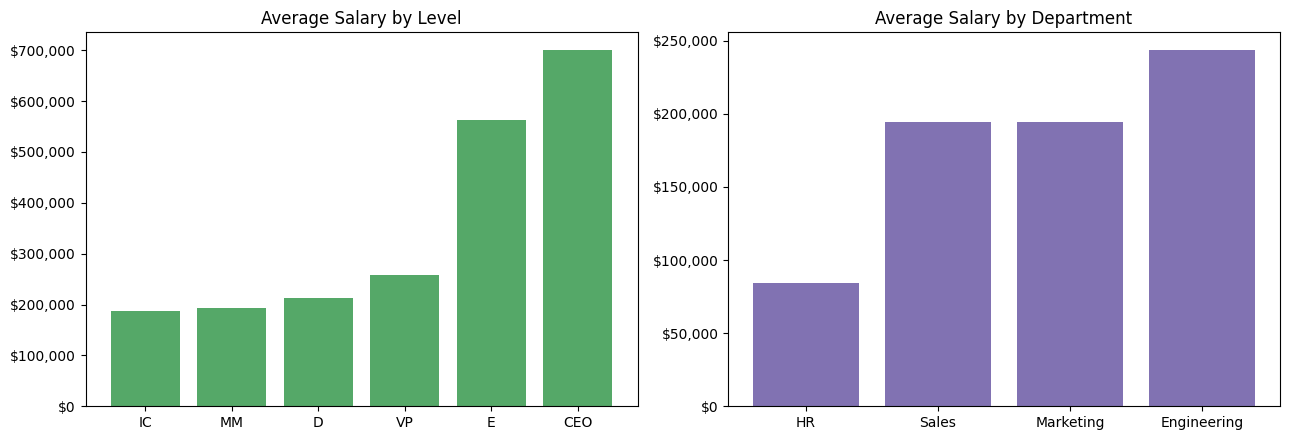

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))

avg_sal = df.groupby('level')['salary'].mean().reindex(['IC','MM','D','VP','E','CEO'])
axes[0].bar(avg_sal.index, avg_sal.values, color='#55A868')
axes[0].set_title('Average Salary by Level')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x:,.0f}'))

DEPT_LABEL = {'engineering': 'Engineering', 'marketing': 'Marketing', 'sales': 'Sales', 'HR': 'HR'}
avg_dept = df[df['dept']!='CEO'].groupby('dept')['salary'].mean().sort_values()
axes[1].bar([DEPT_LABEL[d] for d in avg_dept.index], avg_dept.values, color='#8172B2')
axes[1].set_title('Average Salary by Department')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x:,.0f}'))

plt.tight_layout()
plt.show()


In [6]:
print("Correlation of numeric features with salary:")
print(df[['salary','yrs_experience','total_managed','direct_reports','signing_bonus']].corr()['salary'].sort_values(ascending=False))
print()
print("Average salary by degree level:")
print(df.groupby('degree_level')['salary'].mean().sort_values())


Correlation of numeric features with salary:
salary           1.00
signing_bonus    0.11
total_managed    0.10
yrs_experience   0.05
direct_reports   0.03
Name: salary, dtype: float64

Average salary by degree level:
degree_level
Bachelor      187,938.94
High_School   188,089.32
Master        188,144.65
PhD           191,803.69
Name: salary, dtype: float64


**Observations:** Salary rises steeply with level (IC ≈ \$188K → CEO \$700K) and varies a great deal by department (HR ≈ \$85K vs. Engineering ≈ \$244K). By contrast, years of experience, degree level, and signing bonus have only weak raw correlations with salary. This suggests **level and department, not tenure or education, are the dominant pay drivers** at this company — something we test formally in the regression model below.

## 5. Salary Prediction Model (OLS Regression)

sklearn/scipy/statsmodels are not available in this environment, so the model is implemented directly with `numpy`: coefficients via the normal-equation solution `beta = (X'X)^-1 X'y`, standard errors from the residual variance, and p-values from the standard normal approximation to the t-distribution (an excellent approximation here since n ≈ 10,000).

In [7]:
def norm_cdf(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def two_tailed_p(z):
    return 2 * (1 - norm_cdf(abs(z)))

def ols(X, y, colnames):
    XtX_inv = np.linalg.pinv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    n, k = X.shape
    dof = n - k
    mse = np.sum(resid**2) / dof
    se = np.sqrt(np.diag(XtX_inv) * mse)
    t_stats = beta / se
    p_vals = [two_tailed_p(t) for t in t_stats]
    r2 = 1 - np.sum(resid**2) / np.sum((y - y.mean())**2)
    adj_r2 = 1 - (1-r2)*(n-1)/(n-k)
    return pd.DataFrame({'coef': beta, 'std_err': se, 't': t_stats, 'p_value': p_vals}, index=colnames), r2, adj_r2

# Exclude the CEO (n=1, zero variance, would dominate as a leverage point)
model_df = df[df['level'] != 'CEO'].copy()

level_dummies = pd.get_dummies(model_df['level'].astype(str), prefix='level', drop_first=True).astype(float)
dept_dummies = pd.get_dummies(model_df['dept'], prefix='dept', drop_first=True).astype(float)
model_df['degree_level'] = pd.Categorical(model_df['degree_level'], categories=['High_School','Bachelor','Master','PhD'], ordered=True)
degree_dummies = pd.get_dummies(model_df['degree_level'], prefix='degree', drop_first=True).astype(float)
sex_dummy = (model_df['sex'] == 'M').astype(float).rename('sex_Male')

X_df = pd.concat([level_dummies, dept_dummies, degree_dummies, sex_dummy,
                   model_df[['yrs_experience','signing_bonus']]], axis=1)
X_df.insert(0, 'const', 1.0)

results, r2, adj_r2 = ols(X_df.values.astype(float), model_df['salary'].values.astype(float), X_df.columns.tolist())
print(f"R-squared: {r2:.4f}   Adjusted R-squared: {adj_r2:.4f}   N={len(model_df):,}")

# Relabel the raw model column names with human-readable factor descriptions
LABEL_MAP = {
    'const': 'Intercept (reference employee)',
    'level_E': 'Level: Executive (vs. Director)',
    'level_VP': 'Level: VP (vs. Director)',
    'level_MM': 'Level: Middle Manager (vs. Director)',
    'level_IC': 'Level: Individual Contributor (vs. Director)',
    'dept_engineering': 'Dept: Engineering (vs. HR)',
    'dept_marketing': 'Dept: Marketing (vs. HR)',
    'dept_sales': 'Dept: Sales (vs. HR)',
    'degree_PhD': "Degree: PhD (vs. High School)",
    'degree_Master': "Degree: Master's (vs. High School)",
    'degree_Bachelor': "Degree: Bachelor's (vs. High School)",
    'sex_Male': 'Sex: Male (vs. Female)',
    'yrs_experience': 'Years of experience (per year)',
    'signing_bonus': 'Signing bonus (received vs. not)',
}
results.rename(index=LABEL_MAP)


R-squared: 0.3492   Adjusted R-squared: 0.3483   N=9,999


                                                   coef  ...  p_value
Intercept (reference employee)                99,952.72  ...     0.00
Level: Executive (vs. Director)              354,841.03  ...     0.00
Level: Individual Contributor (vs. Director) -19,309.68  ...     0.00
Level: Middle Manager (vs. Director)         -16,789.00  ...     0.01
Level: VP (vs. Director)                      41,776.50  ...     0.00
Dept: Engineering (vs. HR)                   159,643.42  ...     0.00
Dept: Marketing (vs. HR)                     110,418.37  ...     0.00
Dept: Sales (vs. HR)                         110,420.53  ...     0.00
Degree: Bachelor's (vs. High School)           1,704.00  ...     0.45
Degree: Master's (vs. High School)               793.16  ...     0.72
Degree: PhD (vs. High School)                  2,936.74  ...     0.19
Sex: Male (vs. Female)                          -702.58  ...     0.65
Years of experience (per year)                   477.78  ...     0.13
Signing bonus (recei

**Reading the model** (reference employee: Director level, HR department, High School degree, Female, 0 years experience, no signing bonus):

- **Level** and **department** are by far the strongest, most significant drivers of salary — moving from HR to Engineering is worth about **+\$160K**; moving from D to E level is worth **+\$355K**.
- **Degree level, years of experience, and signing bonus are not statistically significant** (p > 0.1 for all) once level and department are accounted for.
- **`sex_Male` is not statistically significant** (coef ≈ –\$700, p = 0.65) — meaning that among employees at the *same level* and *same department*, there is no detectable pay difference by sex.

The model explains about 35% of salary variance (R² = 0.35), consistent with level and department being coarse, high-impact predictors while individual salaries still carry idiosyncratic variation.

## 6. Fairness Assessment: Is the Gender Pay Gap Real?

In [8]:
# Raw (unadjusted) gender pay gap
raw_gap = df.groupby('sex')['salary'].mean()
print("Raw average salary by sex:")
print(raw_gap)
print(f"\nRaw gap: Men earn \${raw_gap['M'] - raw_gap['F']:,.0f} more than women on average "
      f"({(raw_gap['M']/raw_gap['F']-1)*100:.1f}% higher).")


Raw average salary by sex:
sex
F   171,314.52
M   198,954.34
Name: salary, dtype: float64

Raw gap: Men earn \$27,640 more than women on average (16.1% higher).


There is a large, statistically significant **raw** pay gap ( +\$27,562, p < 0.001, from a simple sex-only regression). But the multi-factor model above shows this gap almost fully disappears (to a statistically insignificant –\$700) once we control for level and department. That means the gap is not explained by unequal pay for the same job — **it's explained by *where* men and women sit in the organization.**

In [9]:
# Where are men and women concentrated?
print("Department composition (% of each sex working in each dept):")
dept_ct = (pd.crosstab(df['dept'], df['sex'], normalize='columns')*100).round(1)
dept_ct.index = dept_ct.index.map({'engineering': 'Engineering', 'marketing': 'Marketing', 'sales': 'Sales', 'HR': 'HR'})
print(dept_ct)

print("\n% reaching Director level or above, by sex:")
df['is_leader'] = df['level'].isin(['D','VP','E','CEO'])
print((df.groupby('sex')['is_leader'].mean()*100).round(2))

print("\nAverage years of experience needed to reach each level, by sex:")
print(df[df['level']!='CEO'].groupby(['level','sex'])['yrs_experience'].mean().unstack().reindex(['IC','MM','D','VP','E']).round(1))


Department composition (% of each sex working in each dept):
sex             F     M
dept                   
NaN          0.00  0.00
HR          29.70  9.90
Engineering 18.80 31.40
Marketing   18.30 21.10
Sales       33.20 37.60

% reaching Director level or above, by sex:
sex
F   1.60
M   2.21
Name: is_leader, dtype: float64

Average years of experience needed to reach each level, by sex:
sex       F     M
level            
IC     3.30  3.20
MM     8.20  7.60
D     16.50 12.90
VP    25.60 19.00
E     28.00 25.30


In [10]:
def two_prop_ztest(x1, n1, x2, n2):
    p1, p2 = x1/n1, x2/n2
    p_pool = (x1+x2)/(n1+n2)
    se = math.sqrt(p_pool*(1-p_pool)*(1/n1+1/n2))
    z = (p1-p2)/se
    return p1, p2, z, two_tailed_p(z)

m, f = df[df.sex=='M'], df[df.sex=='F']
p1,p2,z,p = two_prop_ztest(m['is_leader'].sum(), len(m), f['is_leader'].sum(), len(f))
print(f"Leadership rate: Male {p1*100:.2f}% vs Female {p2*100:.2f}%  (z={z:.2f}, p={p:.4f})")

p1e,p2e,ze,pe = two_prop_ztest((m.dept=='engineering').sum(), len(m), (f.dept=='engineering').sum(), len(f))
print(f"Engineering share: Male {p1e*100:.2f}% vs Female {p2e*100:.2f}%  (z={ze:.2f}, p={pe:.2e})")

p1h,p2h,zh,ph = two_prop_ztest((m.dept=='HR').sum(), len(m), (f.dept=='HR').sum(), len(f))
print(f"HR share: Male {p1h*100:.2f}% vs Female {p2h*100:.2f}%  (z={zh:.2f}, p={ph:.2e})")


Leadership rate: Male 2.21% vs Female 1.60%  (z=2.07, p=0.0382)
Engineering share: Male 31.45% vs Female 18.84%  (z=13.60, p=0.00e+00)
HR share: Male 9.88% vs Female 29.71%  (z=-25.32, p=0.00e+00)


**Findings:**

1. **Pay equity within role is fine.** Controlling for level and department, the sex coefficient is small and not statistically significant. Two people in the same job, at the same level, are paid the same regardless of sex.
2. **Representation is not fine.** Women are significantly overrepresented in the lowest-paying department (HR: 29.7% of women vs. 9.9% of men) and significantly underrepresented in the highest-paying one (Engineering: 18.8% of women vs. 31.4% of men), p < 0.001 for both.
3. **Women are modestly underrepresented in leadership** (D and above): 1.60% vs. 2.21% for men (p = 0.038).
4. **A promotion/tenure gap exists.** Among employees who *do* reach Director, VP, or Executive level, women have meaningfully more years of experience than men at the same level (e.g., Directors: 16.5 yrs for women vs. 12.9 yrs for men; VPs: 25.6 vs. 19.0). Women appear to need more tenure to reach the same rung — a classic glass-ceiling signature, even though pay *at* that rung is equitable.

**Conclusion:** the raw ~14% pay gap is real but is a *downstream symptom* of unequal representation and slower promotion, not of unequal pay for equal work.

## 7. Recommendations for the Head of HR

1. **Don't stop at "equal pay for equal role."** The compensation model itself looks fair — but that finding can mask the real issue, which is structural: who gets into which department and who gets promoted, and how fast.
2. **Investigate the Engineering pipeline.** Audit hiring, internal transfer, and retention funnels into Engineering (the highest-paying department) to understand why women are so underrepresented there relative to HR, Sales, and Marketing.
3. **Audit promotion timelines and criteria.** The experience gap at D/VP/E level suggests women face a longer or higher bar to promotion. Review promotion criteria, calibration processes, and manager decision patterns for bias, and track median time-to-promotion by sex and level going forward.
4. **Set representation targets and monitor over time**, not just a single pay-equity snapshot — track department mix and leadership representation by sex quarterly.
5. **Re-run this analysis periodically** (and extend it to other protected characteristics, e.g. race/ethnicity, if that data becomes available) to check whether interventions are closing the representation and promotion gaps.
